In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style("whitegrid")

In [2]:
data = pd.read_csv("../data/processed_balanced.csv")
y = data["target_encoded"].values
X = data.drop(columns=["target_encoded"])

le = joblib.load("../models/label_encoder.pkl")
feature_columns = joblib.load("../models/feature_columns.pkl")

print("X:", X.shape, "| y:", y.shape)
print("Classes:", list(le.classes_))

X: (33855, 21) | y: (33855,)
Classes: ['Compensated Hypothyroid', 'Hyperthyroid', 'Negative', 'Other Thyroid Condition', 'Primary Hypothyroid']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])

Train: 27084 | Test: 6771


In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest":       RandomForestClassifier(random_state=42),
    "XGBoost":             XGBClassifier(random_state=42, eval_metric="mlogloss"),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    results[name] = acc
    print(f"{name:22s} accuracy: {acc*100:.2f}%")

c:\Users\caitl\Downloads\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression    accuracy: 80.52%
Random Forest          accuracy: 98.07%
XGBoost                accuracy: 98.11%


In [5]:
res = pd.DataFrame({"Accuracy (%)": {k: round(v*100, 2) for k, v in results.items()}})
res = res.sort_values("Accuracy (%)", ascending=False)
res["Rank"] = range(1, len(res) + 1)
res

,Accuracy (%),Rank
XGBoost,98.11,1
Random Forest,98.07,2
Logistic Regression,80.52,3


In [6]:
best_model = models["XGBoost"]
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=le.classes_, digits=2))

                         precision    recall  f1-score   support

Compensated Hypothyroid       0.99      1.00      0.99      1354
           Hyperthyroid       0.99      1.00      0.99      1354
               Negative       0.97      0.95      0.96      1354
Other Thyroid Condition       0.96      0.96      0.96      1355
    Primary Hypothyroid       1.00      1.00      1.00      1354

               accuracy                           0.98      6771
              macro avg       0.98      0.98      0.98      6771
           weighted avg       0.98      0.98      0.98      6771



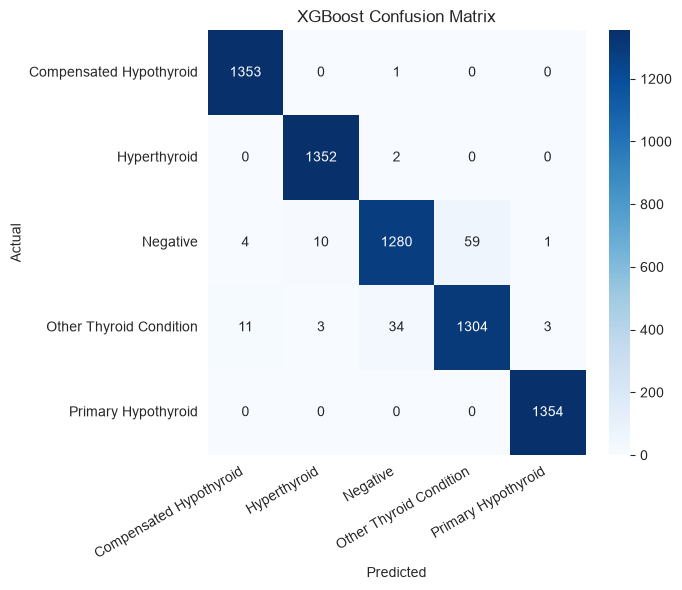

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.xticks(rotation=30, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

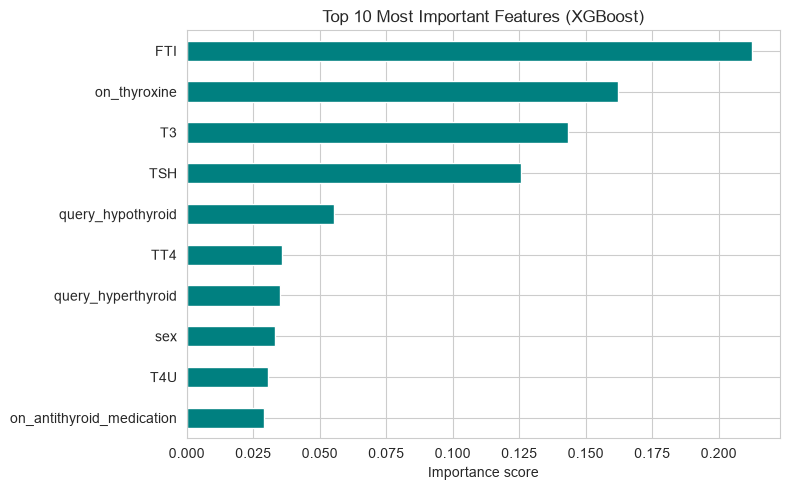

FTI                          0.212
on_thyroxine                 0.162
T3                           0.143
TSH                          0.126
query_hypothyroid            0.055
TT4                          0.036
query_hyperthyroid           0.035
sex                          0.033
T4U                          0.031
on_antithyroid_medication    0.029
dtype: float32

In [8]:
importances = pd.Series(best_model.feature_importances_, index=feature_columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top10[::-1].plot(kind="barh", color="teal")
plt.title("Top 10 Most Important Features (XGBoost)")
plt.xlabel("Importance score")
plt.tight_layout(); plt.show()

top10.round(3)

In [9]:
joblib.dump(best_model, "../models/xgb_model.pkl")
print("Saved ../models/xgb_model.pkl")
print("Model files ready for the app:")
print("  - xgb_model.pkl")
print("  - label_encoder.pkl")
print("  - feature_columns.pkl")

Saved ../models/xgb_model.pkl
Model files ready for the app:
  - xgb_model.pkl
  - label_encoder.pkl
  - feature_columns.pkl
